Train shape: (60000, 785)
Test shape: (10000, 785)
Missing values in train: 0
Pixel range: 0 to 255

Digit counts in train:
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


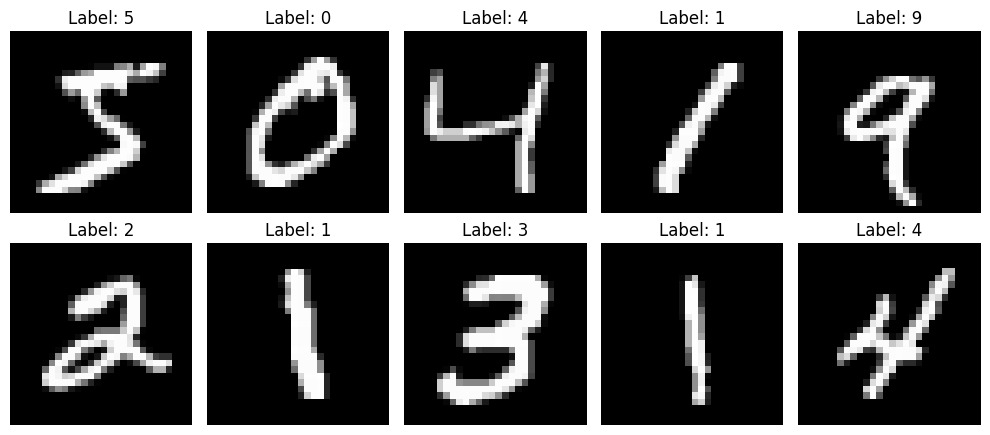

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("mnist_train.csv")
test_df = pd.read_csv("mnist_test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Missing values in train:", train_df.isnull().sum().sum())
print("Pixel range:", train_df.iloc[:, 1:].values.min(), "to", train_df.iloc[:, 1:].values.max())
print("\nDigit counts in train:")
print(train_df["label"].value_counts().sort_index())

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    image = train_df.iloc[i, 1:].values.reshape(28, 28)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {train_df.iloc[i, 0]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

X_train_full = train_df.drop(columns=["label"]).values.astype("float32") / 255.0
y_train_full = train_df["label"].values
X_test = test_df.drop(columns=["label"]).values.astype("float32") / 255.0
y_test = test_df["label"].values

X_train_full = X_train_full.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Pixel range after scaling:", X_train.min(), "to", X_train.max())

Train: (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Test: (10000, 28, 28, 1) (10000,)
Pixel range after scaling: 0.0 to 1.0


In [4]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=8,
    batch_size=128,
    validation_data=(X_val, y_val),
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 100ms/step - accuracy: 0.9274 - loss: 0.2437 - val_accuracy: 0.9772 - val_loss: 0.0752
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.9793 - loss: 0.0680 - val_accuracy: 0.9838 - val_loss: 0.0583
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 98ms/step - accuracy: 0.9847 - loss: 0.0491 - val_accuracy: 0.9873 - val_loss: 0.0447
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9871 - loss: 0.0393 - val_accuracy: 0.9865 - val_loss: 0.0477
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 98ms/step - accuracy: 0.9901 - loss: 0.0320 - val_accuracy: 0.9883 - val_loss: 0.0419
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 98ms/step - accuracy: 0.9910 - loss: 0.0282 - val_accuracy: 0.9895 - val_loss: 0.0344
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - accuracy: 0.9924 - loss: 0.0231 - val_accuracy: 0.9873 - val_loss: 0.0454
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9931 - loss: 0.0206 - val_a

Test accuracy: 0.9904
Test loss: 0.0264

              precision    recall  f1-score   support

           0      0.992     0.996     0.994       980
           1      0.997     0.994     0.996      1135
           2      0.991     0.995     0.993      1032
           3      0.983     0.992     0.988      1010
           4      0.990     0.996     0.993       982
           5      0.978     0.990     0.984       892
           6      0.996     0.980     0.988       958
           7      0.992     0.987     0.990      1028
           8      0.992     0.992     0.992       974
           9      0.991     0.981     0.986      1009

    accuracy                          0.990     10000
   macro avg      0.990     0.990     0.990     10000
weighted avg      0.990     0.990     0.990     10000



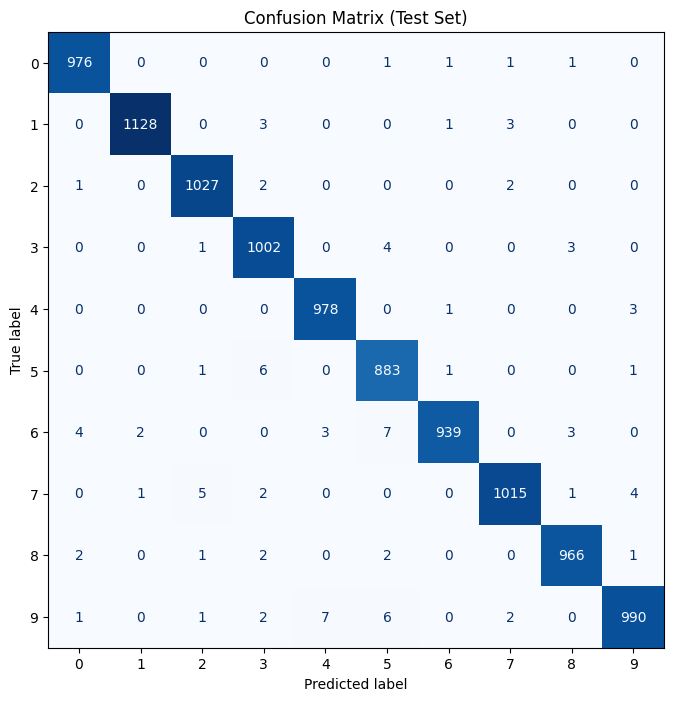

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", round(test_acc, 4))
print("Test loss:", round(test_loss, 4))

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print()
print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.show()

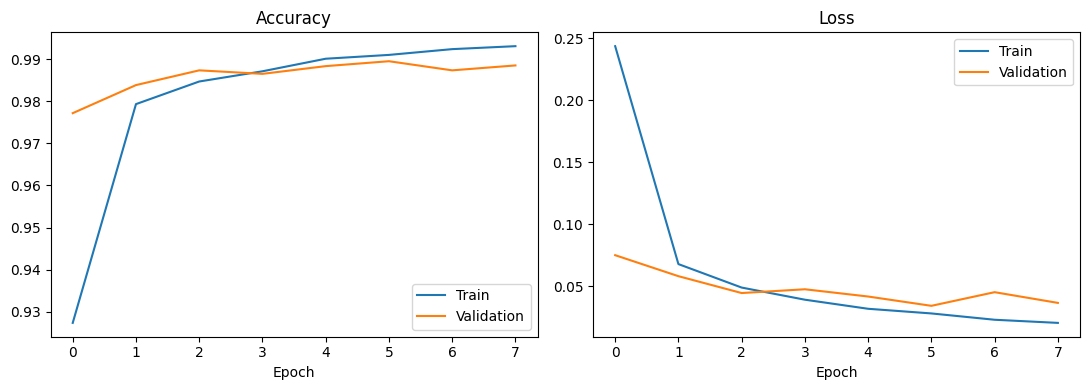

Wrong predictions: 96


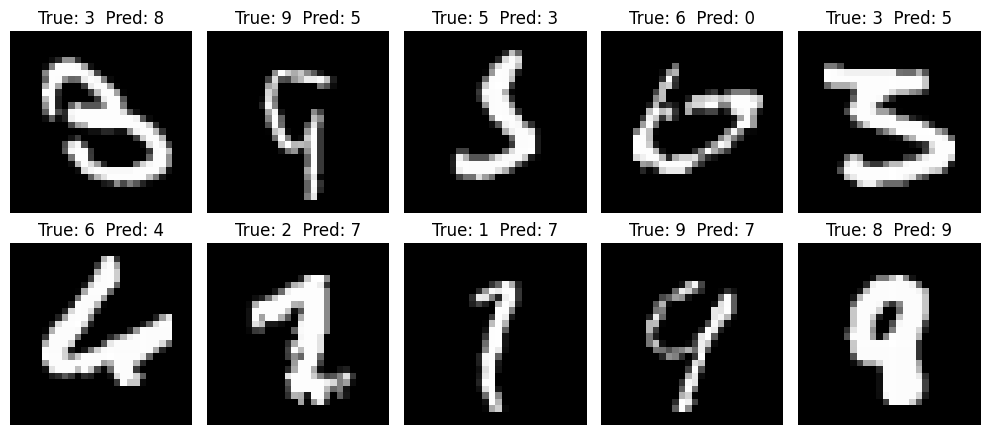

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

wrong = np.where(y_pred != y_test)[0]
print("Wrong predictions:", len(wrong))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"True: {y_test[idx]}  Pred: {y_pred[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()